In [1]:
import sys
import pystac_client
import planetary_computer
import matplotlib.pyplot as plt

import numpy as np
import xarray as xr 
from scipy.ndimage import uniform_filter


import datacube
import odc.stac
from odc.geo.geom import BoundingBox

sys.path.insert(1, "../Tools/")
from dea_tools.datahandling import load_ard
from dea_tools.plotting import display_map

In [2]:
# -28.79433,153.25317

# -28.78212,153.23947
# -28.84756,153.35528

x = (153.23947, 153.30528)
y = (-28.84756, -28.78212)
time = ("2017-02", "2017-05")

In [3]:
display_map(x=x, y=y)

*Load data from Planetary Computer*

In [4]:
# Open a client pointing to the Microsoft Planetary Computer data catalogue
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

In [5]:
# Convert data-cube style queries into something readable by `pystac_client`
bbox = BoundingBox.from_xy(x, y)
time_range = "/".join(time)

# Search for STAC items from "sentinel-1-rtc" product
search = catalog.search(
    collections="sentinel-1-rtc",
    bbox=bbox,
    datetime=time_range,
)

# Check how many items were returned
items = search.item_collection()
print(f"Found {len(items)} STAC items")

Found 20 STAC items


In [6]:
# Load ESA WorldCover data with odc-stac
rtc = odc.stac.load(
    items,
    bbox=bbox,
    bands=["vv", "vh"],
    crs="EPSG:3577",
    resolution=30,
)

In [7]:
rtc

<xarray.Dataset> Size: 11MB
Dimensions:      (y: 277, x: 251, time: 20)
Coordinates:
  * y            (y) float64 2kB -3.297e+06 -3.297e+06 ... -3.305e+06 -3.305e+06
  * x            (x) float64 2kB 2.038e+06 2.038e+06 ... 2.046e+06 2.046e+06
    spatial_ref  int32 4B 3577
  * time         (time) datetime64[ns] 160B 2017-02-01T19:14:02.094917 ... 20...
Data variables:
    vv           (time, y, x) float32 6MB 0.3826 0.1504 ... 0.1104 0.04947
    vh           (time, y, x) float32 6MB 0.0601 0.02581 ... 0.02384 0.02703

In [8]:
def dB_scale(data): 
    '''Scales a xarray.DataArray with linear DN to a dB scale.'''
    # Explicitly set negative data to nan to avoid log of negative number
    negative_free_data = data.where(data >= 0, np.nan)
    return 10 * np.log10(negative_free_data)

# Visualise RTC samples

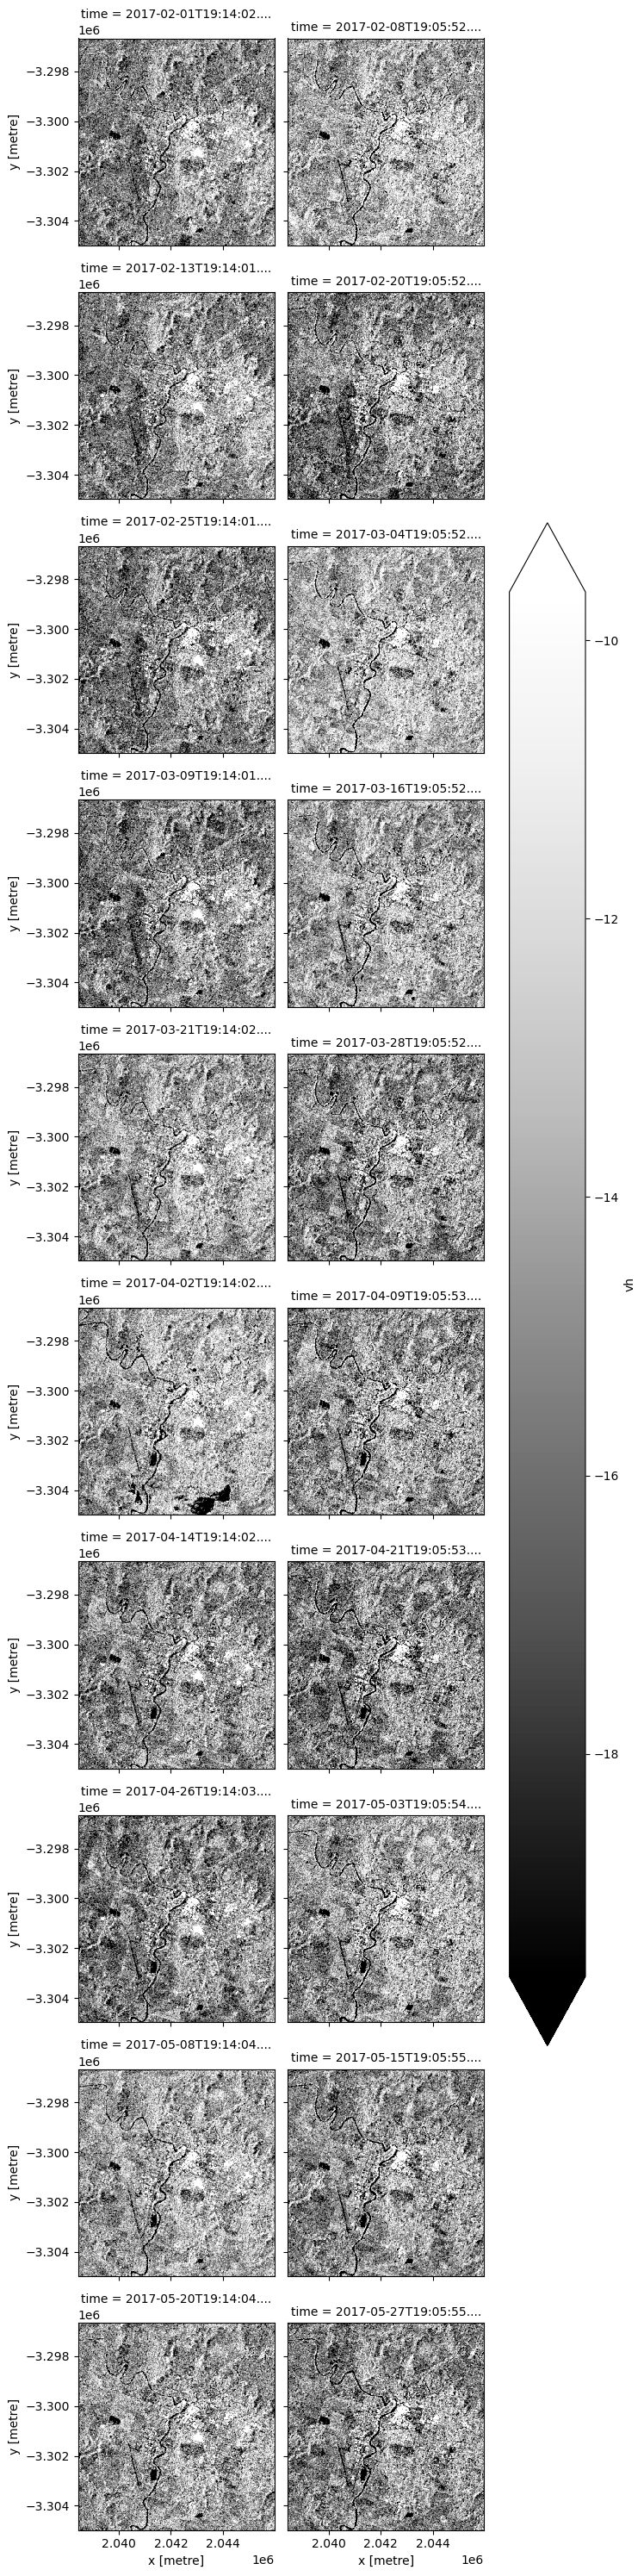

In [9]:
# Scale to plot data in decibels
rtc_db = {"vh": dB_scale(rtc.vh), "vv": dB_scale(rtc.vv)}

# Plot all VH observations for the year
rtc_db["vh"].plot(cmap="Greys_r", robust=True, col="time", col_wrap=2)
plt.show()

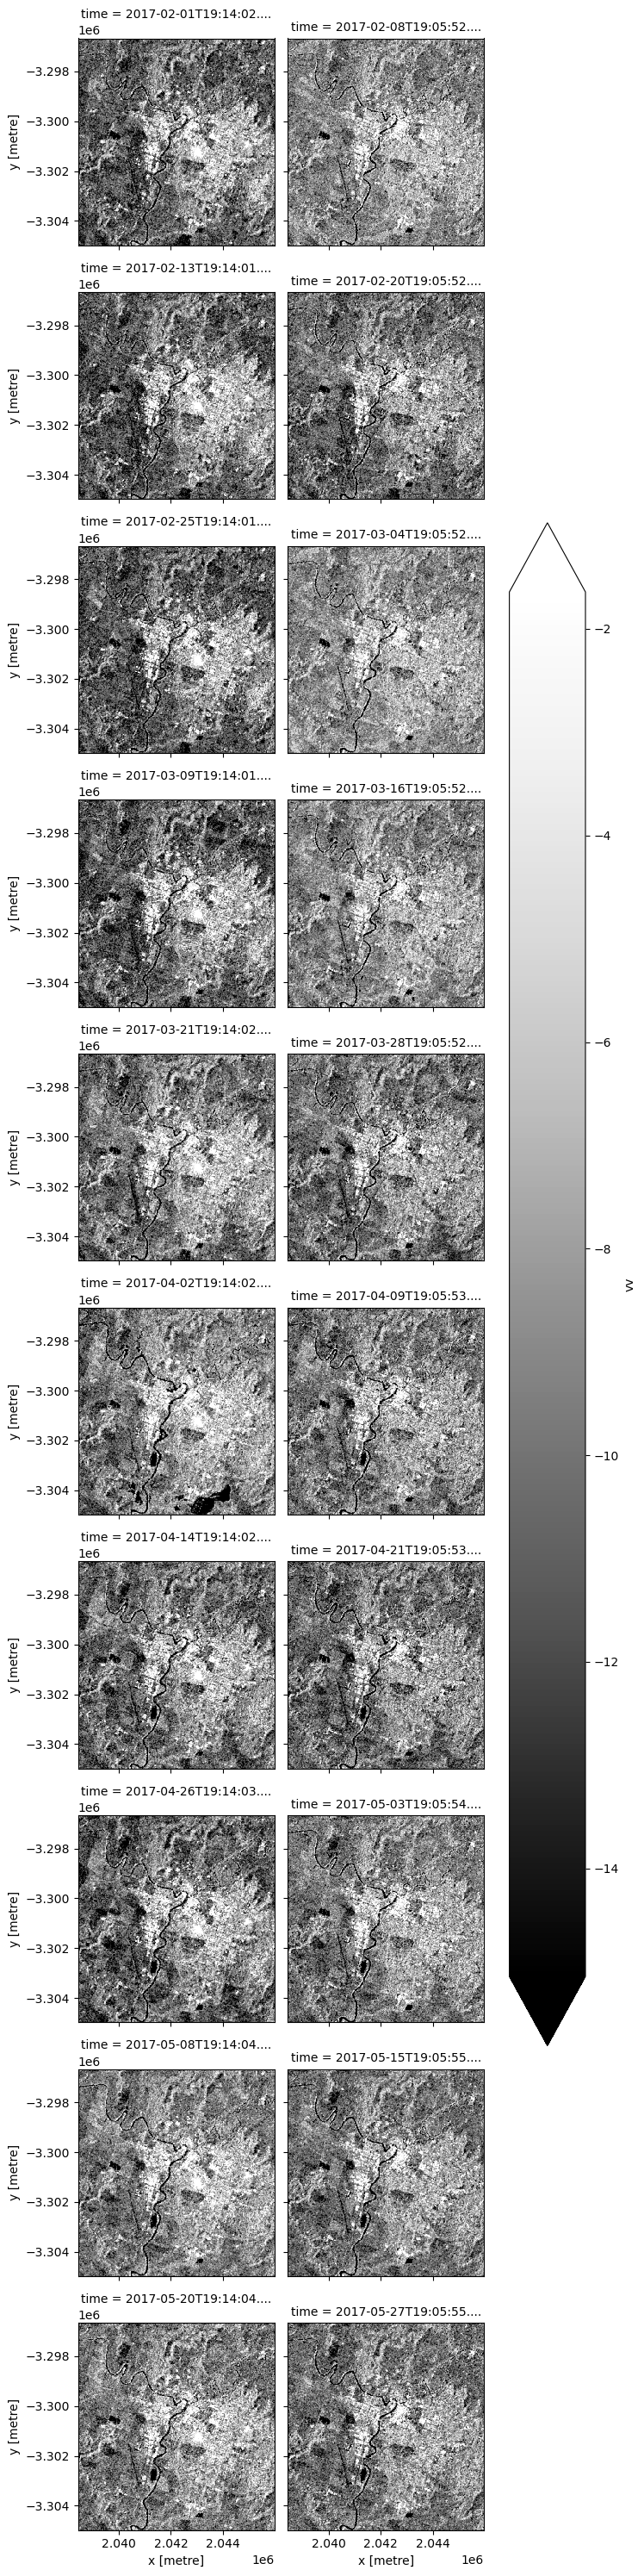

In [10]:
# Scale to plot data in decibels
# Plot all VH observations for the year
rtc_db["vv"].plot(cmap="Greys_r", robust=True, col="time", col_wrap=2)
plt.show()

## Apply Lee speckle filter

In [22]:
# Code from Radar_water_detection.ipynb
# Adapted from https://stackoverflow.com/questions/39785970/speckle-lee-filter-in-python
def lee_filter(img, size):
    """
    Applies the Lee filter to reduce speckle noise in an image.

    Parameters:
    img (ndarray): Input image to be filtered.
    size (int): Size of the uniform filter window.

    Returns:
    ndarray: The filtered image.
    """
    img_mean = uniform_filter(img, size)
    img_sqr_mean = uniform_filter(img**2, size)
    img_variance = img_sqr_mean - img_mean**2

    overall_variance = np.var(img)

    img_weights = img_variance / (img_variance + overall_variance)
    img_output = img_mean + img_weights * (img - img_mean)
    return img_output

# Define a function to apply the Lee filter to a DataArray
def apply_lee_filter(data_array, size=7):
    """
    Applies the Lee filter to the provided DataArray.

    Parameters:
    data_array (xarray.DataArray): The data array to be filtered.
    size (int): Size of the uniform filter window. Default is 7.

    Returns:
    xarray.DataArray: The filtered data array.
    """
    data_array_filled = data_array.fillna(0)
    filtered_data = xr.apply_ufunc(
        lee_filter, data_array_filled,
        kwargs={"size": size},
        input_core_dims=[["y", "x"]],
        output_core_dims=[["y", "x"]],
        dask_gufunc_kwargs={"allow_rechunk": True},
        vectorize=True,
        dask="parallelized",
        output_dtypes=[data_array.dtype]
    )
    return filtered_data

In [25]:
# Apply the Lee filter to both VV and VH data
rtc["filtered_vv"] = apply_lee_filter(rtc['vv'], size = 7)
rtc["filtered_vh"] = apply_lee_filter(rtc['vh'], size = 7)


rtc_db["filtered_vv"] = dB_scale(rtc["filtered_vv"])
rtc_db["filtered_vh"] = dB_scale(rtc["filtered_vh"])

## Approach A - Classify then change-detect

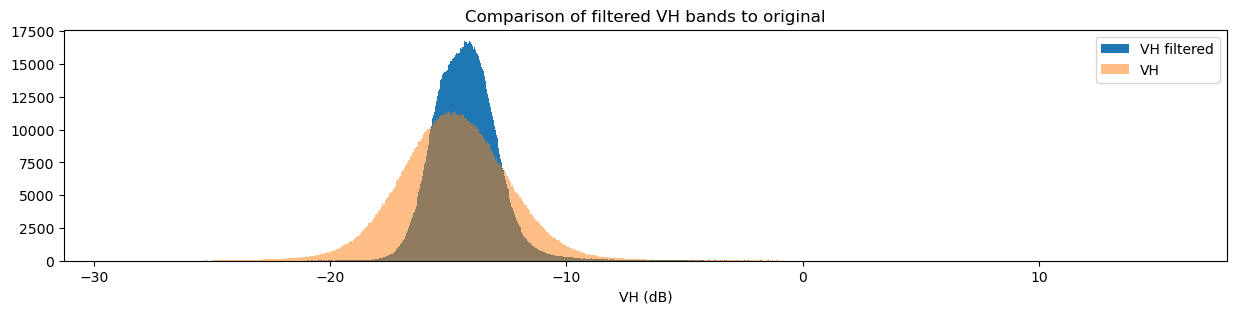

In [28]:
fig = plt.figure(figsize=(15, 3))
rtc_db["filtered_vh"].plot.hist(bins=1000, label="VH filtered")
rtc_db["vh"].plot.hist(bins=1000, label="VH", alpha=0.5)
plt.legend()
plt.xlabel("VH (dB)")
plt.title("Comparison of filtered VH bands to original")
plt.show()

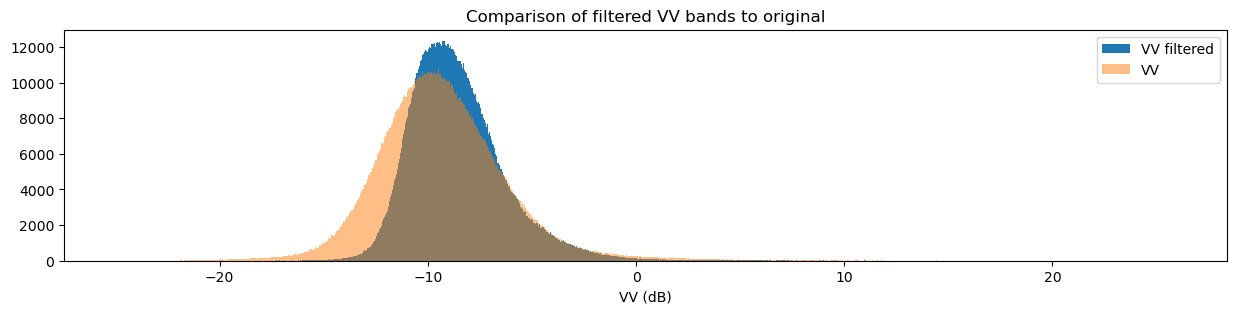

In [30]:
fig = plt.figure(figsize=(15, 3))
rtc_db["filtered_vv"].plot.hist(bins=1000, label="VV filtered")
rtc_db["vv"].plot.hist(bins=1000, label="VV", alpha=0.5)
plt.legend()
plt.xlabel("VV (dB)")
plt.title("Comparison of filtered VV bands to original")
plt.show()